3.1

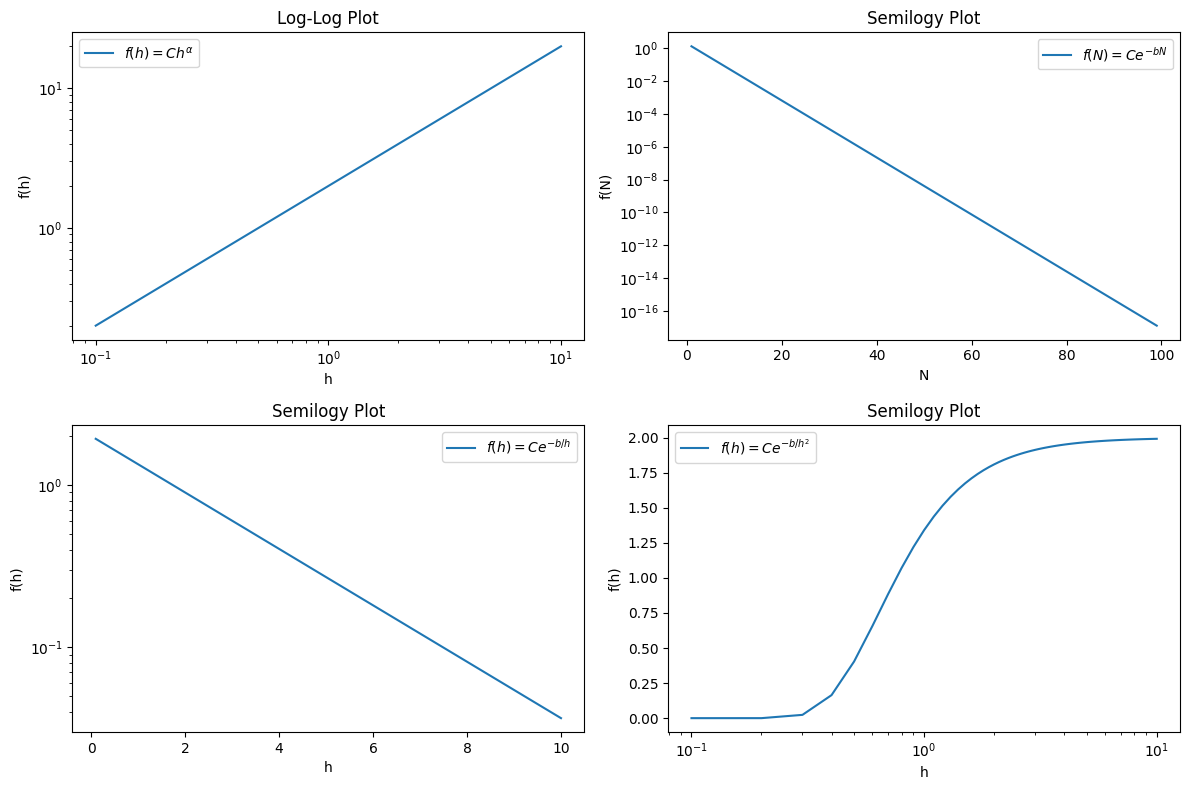

In [1]:
import numpy as np
import matplotlib.pyplot as plt

C = 2
alpha = 1
b = 0.4

# Own variables
h = np.linspace(0.1, 10, 100)
N = np.arange(1, 100)

# 1. function f(h) = C * h^α (log-log plot)
f_h = C * h**alpha

# 2. Exponential function f(N) = C * exp(-b*N) (semilog-y plot)
f_exp = C * np.exp(-b * N)

# 3. Function f(h) = C * exp(-b/h) (semilog-y plot)
f_exp_inv = C * np.exp(-b / h)

# 4. Function f(h^2) = C * exp(-b/h^2) (semilog-y plot)
f_exp_inv2 = C * np.exp(-b / h**2)

# Plotting
plt.figure(figsize=(12, 8))

# Log-log plot for power-law
plt.subplot(2, 2, 1)
plt.loglog(h, f_h, label=r'$f(h) = Ch^\alpha$')
plt.xlabel('h')
plt.ylabel('f(h)')
plt.title('Log-Log Plot')
plt.legend()

# Semilogy plot for exponential decay
plt.subplot(2, 2, 2)
plt.semilogy(N, f_exp, label=r'$f(N) = Ce^{-bN}$')
plt.xlabel('N')
plt.ylabel('f(N)')
plt.title('Semilogy Plot')
plt.legend()

# Semilogy plot for f(h) = Ce^{-b/h}
plt.subplot(2, 2, 3)
plt.semilogy(1/h, f_exp_inv, label=r'$f(h) = Ce^{-b/h}$')
plt.xlabel('h')
plt.ylabel('f(h)')
plt.title('Semilogy Plot')
plt.legend()

# Semilogy plot for f(h) = Ce^{-b/h^2}
plt.subplot(2, 2, 4)
plt.semilogx(h, f_exp_inv2, label=r'$f(h) = Ce^{-b/h^2}$')
plt.xlabel('h')
plt.ylabel('f(h)')
plt.title('Semilogy Plot')
plt.legend()

plt.tight_layout()
plt.show()

3.2

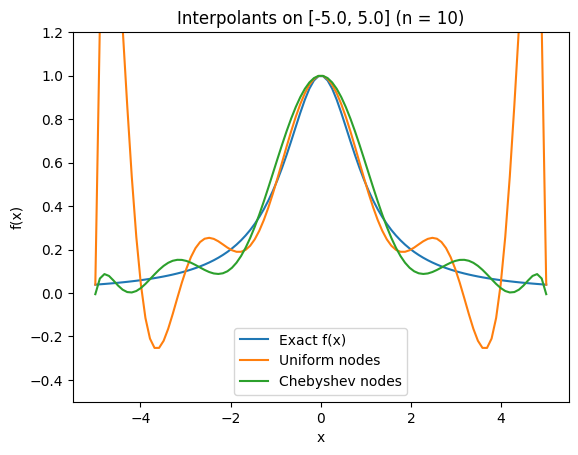

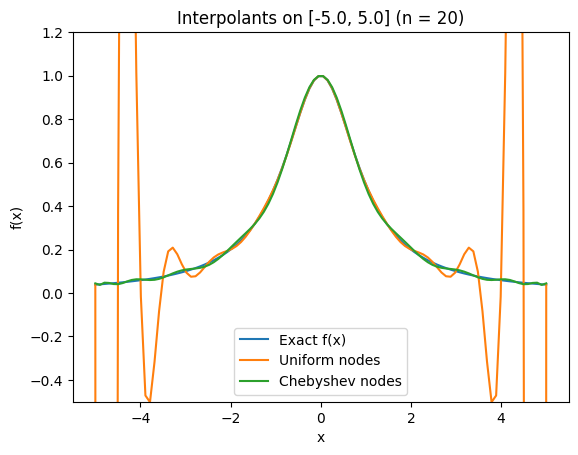

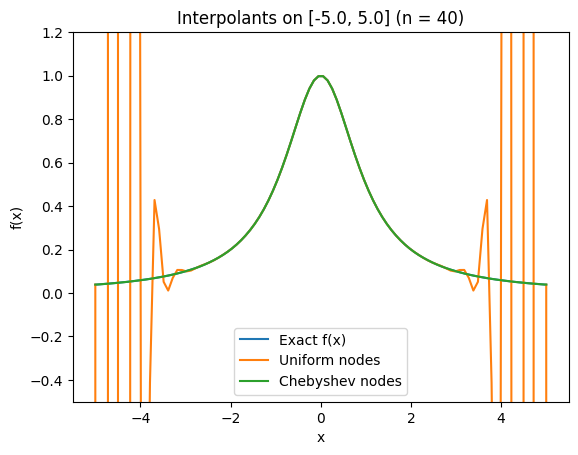

b = 0.6347490790039367
C = 0.032855522826694246


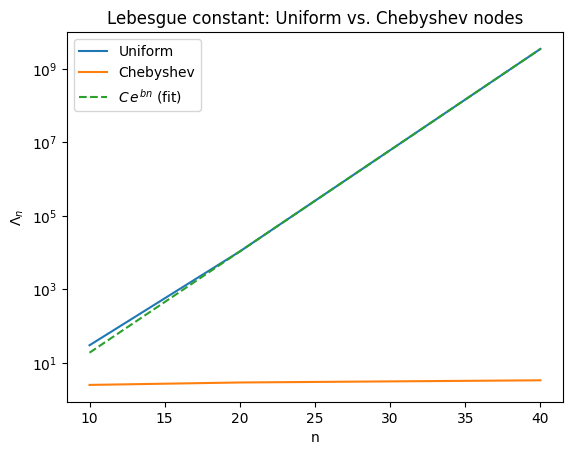

In [5]:
# Settings
NS = [10, 20, 40]       # number of subintervals → n+1 interpolation nodes
A, B = -5.0, 5.0        # interpolation interval
X_EVAL = np.linspace(A, B, 100)  # evaluation grid for plots & Lebesgue const

# Core utilities
def f(x: np.ndarray) -> np.ndarray:
    return 1.0 / (1.0 + x**2)


def neville(x_nodes, y_nodes, x_eval, return_table=False):
    """
    Neville's algorithm for polynomial interpolation.

    Parameters
    ----------
    x_nodes : array-like
        Interpolation nodes (length n+1).
    y_nodes : array-like
        Function values at the nodes (same length as x_nodes).
    x_eval : float
        Point where the interpolant is evaluated.
    return_table : bool, optional
        If True, also return the full Neville table (n+1 x n+1).

    Returns
    -------
    p : float
        Interpolated value at x_eval.
    table : ndarray (optional)
        The full Neville table. table[0, -1] is the final value.
    """
    x_nodes = np.asarray(x_nodes, dtype=float)
    y_nodes = np.asarray(y_nodes, dtype=float)

    if x_nodes.shape != y_nodes.shape:
        raise ValueError("x_nodes and y_nodes must have the same length.")

    n = x_nodes.size
    # p[:, 0] holds the function values; upper-right triangle gets filled
    table = np.zeros((n, n), dtype=float)
    table[:, 0] = y_nodes

    # Fill columns left→right, using only previously computed entries
    for m in range(1, n):
        # Each subsequent column is one element shorter
        for j in range(0, n - m):
            xj, xjm = x_nodes[j], x_nodes[j + m]
            num = (x_eval - xj) * table[j + 1, m - 1] - (x_eval - xjm) * table[j, m - 1]
            den = (xjm - xj)
            table[j, m] = num / den

    if return_table:
        return table[0, -1], table
    return table[0, -1]


def uniform_nodes(a: float, b: float, n: int) -> np.ndarray:
    """n+1 uniform nodes on [a, b]."""
    return np.linspace(a, b, n + 1)

def _barycentric_weights(x_nodes):
    x = np.asarray(x_nodes, dtype=float)
    n = len(x)
    w = np.ones(n, dtype=float)
    for i in range(n):
        diff = x[i] - np.delete(x, i)
        if np.any(diff == 0.0):
            raise ZeroDivisionError("Duplicate nodes.")
        w[i] = 1.0 / np.prod(diff)
    return w

def _lebesgue_function(x_nodes, x_eval):
    x_nodes = np.asarray(x_nodes, dtype=float)
    x_eval = np.asarray(x_eval, dtype=float)
    w = _barycentric_weights(x_nodes)
    X = x_eval[..., None]
    Xdiff = X - x_nodes[None, :]
    at_node = np.isclose(Xdiff, 0.0)
    any_at_node = at_node.any(axis=-1)
    Lambda = np.empty(X.shape[:-1], dtype=float)
    mask = ~any_at_node
    if np.any(mask):
        Xdiff_m = Xdiff[mask]
        num = np.abs(w / Xdiff_m)
        denom = np.abs(np.sum(w / Xdiff_m, axis=-1))
        Lambda[mask] = np.sum(num, axis=-1) / denom
    Lambda[any_at_node] = 1.0
    return Lambda

def lebesgue_const(x_eval_grid, x_nodes):
    return float(np.max(_lebesgue_function(x_nodes, x_eval_grid)))


def chebyshev_nodes_first_kind(a: float, b: float, n: int) -> np.ndarray:
    """
    n+1 Chebyshev nodes of the first kind scaled to [a, b]:
    x_k = cos( (2k+1)π / (2(n+1)) ), k=0..n, then linearly map from [-1,1] to [a,b].
    """
    k = np.arange(0, n + 1)
    x = np.cos(np.pi * (2 * k + 1) / (2 * (n + 1)))  # in [-1, 1]
    # Affine map from [-1,1] to [a,b]
    return 0.5 * (a + b) + 0.5 * (b - a) * x


# a) Build and plot interpolants for n in NS
f_exact = f(X_EVAL)

lebesgue_uniform = []
lebesgue_cheb = []

for n in NS:
    # Nodes and data values
    x_uni = uniform_nodes(A, B, n)
    x_che = chebyshev_nodes_first_kind(A, B, n)
    f_uni = f(x_uni)
    f_che = f(x_che)

    # Evaluate interpolants on the grid via Neville
    f_uni_eval = [neville(x_uni, f_uni, xv) for xv in X_EVAL]
    f_che_eval = [neville(x_che, f_che, xv) for xv in X_EVAL]

    # Plot exact vs. both interpolants
    plt.figure()
    plt.title(f"Interpolants on [{A}, {B}] (n = {n})")
    plt.plot(X_EVAL, f_exact, label="Exact f(x)")
    plt.plot(X_EVAL, f_uni_eval, label="Uniform nodes")
    plt.plot(X_EVAL, f_che_eval, label="Chebyshev nodes")
    plt.ylim(-0.5, 1.2)
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.legend()
    plt.show()

    # b) Lebesgue constants on the same evaluation grid
    # (using your provided fn.lebesgue_const)
    lebesgue_uniform.append(lebesgue_const(X_EVAL, x_uni))
    lebesgue_cheb.append(lebesgue_const(X_EVAL, x_che))

# c) Fit Λ_n ≈ C · e^{b n} to the UNIFORM Lebesgue constants
#     using the last two data points (n = 20, 40)
# Take logs and do a linear fit in n
coeffs = np.polyfit([20, 40], np.log(lebesgue_uniform[1:]), deg=1)
b = coeffs[0]
C = np.exp(coeffs[1])

print(f"b = {b}")
print(f"C = {C}")

# Plot Lebesgue constants and the exponential fit
plt.figure()
plt.title("Lebesgue constant: Uniform vs. Chebyshev nodes")
plt.semilogy(NS, lebesgue_uniform, label="Uniform")
plt.semilogy(NS, lebesgue_cheb, label="Chebyshev")
plt.plot(NS, [C * np.exp(b * n) for n in NS], linestyle="dashed", label=r"$C\,e^{b n}$ (fit)")
plt.ylabel(r"$\Lambda_n$")
plt.xlabel("n")
plt.legend()
plt.show()


3.3

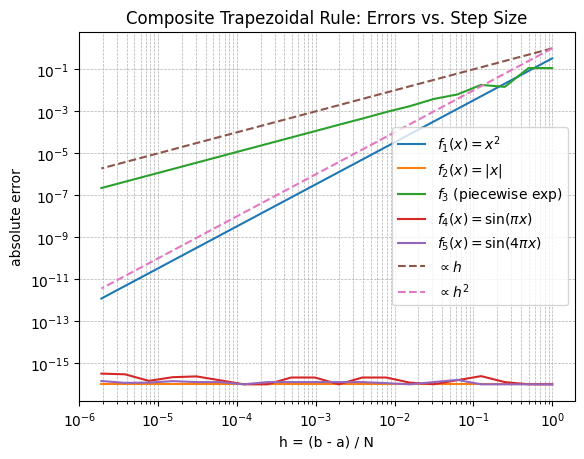

In [6]:

# Problem setup
a, b = -1.0, 1.0
Ns = [2**i for i in range(1, 21)]         # N = 2, 4, ..., 2^20
h_vals = (b - a) / np.array(Ns, dtype=float)

# Composite trapezoidal rule (vectorized)
def composite_trapezoidal(a: float, b: float, N: int, f) -> float:
    """
    Composite trapezoidal rule for ∫_a^b f(x) dx using N panels (N+1 nodes).
    Works with functions f that accept NumPy arrays.
    """
    h = (b - a) / N
    x = np.linspace(a, b, N + 1)
    y = f(x)
    # trapezoidal sum: h * [0.5*y0 + y1 + ... + y_{N-1} + 0.5*yN]
    return h * (0.5 * y[0] + np.sum(y[1:-1]) + 0.5 * y[-1])

# Test functions (array-safe)
def f1(x):
    x = np.asarray(x)
    return x**2

def f2(x):
    x = np.asarray(x)
    return np.abs(x)

def f3(x):
    """
    Piecewise:
        0.5 * exp(x),  x < 1/3
        exp(x),        x >= 1/3
    """
    x = np.asarray(x)
    return np.where(x < 1/3, 0.5 * np.exp(x), np.exp(x))

def f4(x):
    x = np.asarray(x)
    return np.sin(np.pi * x)

def f5(x):
    x = np.asarray(x)
    return np.sin(4 * np.pi * x)

# Ground-truth integrals on [-1, 1]
I1 = 2.0 / 3.0
I2 = 1.0
I3 = np.e - 0.5 * (np.e**(1/3) + np.e**(-1))     # derived from piecewise definition
I4 = 0.0                                         # one full sine period on [-1,1]
I5 = 0.0                                         # two full periods on [-1,1]
I_exact = [I1, I2, I3, I4, I5]

# Compute errors for each N
errors_f1, errors_f2, errors_f3, errors_f4, errors_f5 = [], [], [], [], []

for N in Ns:
    errors_f1.append(abs(I1 - composite_trapezoidal(a, b, N, f1)))
    errors_f2.append(abs(I2 - composite_trapezoidal(a, b, N, f2)))
    errors_f3.append(abs(I3 - composite_trapezoidal(a, b, N, f3)))
    errors_f4.append(abs(I4 - composite_trapezoidal(a, b, N, f4)))
    errors_f5.append(abs(I5 - composite_trapezoidal(a, b, N, f5)))

errors_f1 = np.array(errors_f1)
errors_f2 = np.array(errors_f2)
errors_f3 = np.array(errors_f3)
errors_f4 = np.array(errors_f4)
errors_f5 = np.array(errors_f5)

# Plot (log-log): error vs h with reference slopes h and h^2
# Note: add a tiny epsilon to avoid log(0) for functions that can integrate to machine zero.
epsilon = 1e-16

plt.title("Composite Trapezoidal Rule: Errors vs. Step Size")
plt.xlabel("h = (b - a) / N")
plt.ylabel("absolute error")
plt.loglog(h_vals, errors_f1 + 0.0,              label=r"$f_1(x)=x^2$")
plt.loglog(h_vals, errors_f2 + epsilon,           label=r"$f_2(x)=|x|$")
plt.loglog(h_vals, errors_f3 + 0.0,               label=r"$f_3$ (piecewise exp)")
plt.loglog(h_vals, errors_f4 + epsilon,           label=r"$f_4(x)=\sin(\pi x)$")
plt.loglog(h_vals, errors_f5 + epsilon,           label=r"$f_5(x)=\sin(4\pi x)$")

# Reference lines (shape only; constants arbitrary)
plt.loglog(h_vals, h_vals,        ls="--", label=r"$\propto h$")
plt.loglog(h_vals, h_vals**2,     ls="--", label=r"$\propto h^2$")

plt.legend()
plt.grid(True, which="both", ls="--", lw=0.5)
plt.show()


3.4
is done on ipad